<a href="https://colab.research.google.com/github/digitalmarket-arch/MyAiModel/blob/main/lessons/lesson01_rain_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 1 — Watch a tiny model learn 🌧️

**Goal:** train a model that has only **2 knobs**, and *watch* the knobs change while it learns.

**Time:** about 45–60 minutes &nbsp;•&nbsp; **Cost:** ₹0 (free Google Colab, no GPU needed) &nbsp;•&nbsp; **Coding needed:** none — you only run cells and change numbers

**By the end you will have seen, with your own eyes:**
1. A model with random knobs that guesses badly.
2. One "nudge" in slow motion — exactly how a knob moves, and why.
3. 60 rounds of training, with the knobs printed as a table and drawn as graphs.
4. What happens when the knobs move too slowly, or too fast.

## How to use this notebook (read this if you are new to Colab)

- This page is made of **cells**. Text cells (like this one) explain things. **Code cells** have a grey background.
- **To run a code cell:** click inside it, then press **Shift + Enter** (or click the ▶ button on its left). The result appears just below the cell.
- **Run the cells in order, from top to bottom.** Later cells use things created by earlier cells.
- Inside code, any line starting with `#` is a **comment** — a note for humans that the computer ignores. Read the comments: they explain the code in plain English.
- The first time you run a cell, Colab takes a few seconds to connect to a free computer. If it warns *"This notebook was not authored by Google"*, that's normal for notebooks from GitHub — click **Run anyway**.
- **You cannot break anything.** If things get confusing, use the menu **Runtime → Restart session and run all** to start fresh.
- To keep your own copy with your changes: **File → Save a copy in Drive**.

> **Hinglish mein:** Grey box = code cell. Usme click karo, **Shift + Enter** dabao, aur result neeche dekho. Upar se neeche, order mein chalao. Kuch bhi kharab nahi hoga — ghabraana nahi!

## Quick recap: what is a model?

- A **model** is a formula with adjustable numbers inside it. These numbers are called **parameters**. We call them **knobs**, like the knobs on a radio.
- To make a **guess**, the model multiplies each input by its knob and adds everything up. The result is a **score**.
- **Training** = start with random knobs → guess → measure how wrong the guess was (the **loss**) → nudge the knobs a little → repeat many times.

Our rain model has **2 inputs** and **2 knobs**:

```
rain score = clouds × clouds_knob  +  cold_wind × wind_knob
```

If the rain score is **0.5 or more**, the model says **"Rain"**. Otherwise it says **"No rain"**.

A knob tells you **how much its input matters**. A big knob means "this input pushes strongly towards rain". A knob near 0 means "this input hardly matters". A negative knob means "this input pushes *against* rain".

> **Hinglish mein:** Model ek formula hai jisme kuch adjustable numbers (knobs) hain. Har input × uska knob, phir sab jodo → score. Training matlab knobs ko dheere-dheere sahi jagah tak ghumana.

## Step 1 — The data: 12 days of weather

For each day we wrote down:
- **clouds** — from 0 (clear blue sky) to 1 (completely cloudy)
- **cold wind** — from 0 (no wind) to 1 (strong cold wind)
- **rained** — 1 means it rained, 0 means it didn't

This is our **training data**: examples where we already know the right answer. (The numbers are made up, but they behave like real weather.)

In [1]:
# Our 12 days of weather. Each line is one day:  (clouds, cold_wind, rained)
days = [
    (0.9, 0.9, 1),   # day 1
    (0.1, 0.1, 0),   # day 2
    (0.8, 0.3, 1),   # day 3
    (0.1, 0.9, 0),   # day 4
    (0.6, 0.8, 1),   # day 5
    (0.3, 0.3, 0),   # day 6
    (0.5, 1.0, 1),   # day 7
    (0.5, 0.0, 0),   # day 8
    (1.0, 0.5, 1),   # day 9
    (0.0, 0.4, 0),   # day 10
    (0.7, 0.5, 1),   # day 11
    (0.4, 0.5, 0),   # day 12
]

# Print the days as a neat table
print("Day | Clouds | Cold wind | Rained?")
print("----+--------+-----------+--------")
for day_number, (clouds, wind, rained) in enumerate(days, start=1):
    print(f"{day_number:>3} |  {clouds:.1f}   |    {wind:.1f}    | {'Yes' if rained == 1 else 'No'}")

Day | Clouds | Cold wind | Rained?
----+--------+-----------+--------
  1 |  0.9   |    0.9    | Yes
  2 |  0.1   |    0.1    | No
  3 |  0.8   |    0.3    | Yes
  4 |  0.1   |    0.9    | No
  5 |  0.6   |    0.8    | Yes
  6 |  0.3   |    0.3    | No
  7 |  0.5   |    1.0    | Yes
  8 |  0.5   |    0.0    | No
  9 |  1.0   |    0.5    | Yes
 10 |  0.0   |    0.4    | No
 11 |  0.7   |    0.5    | Yes
 12 |  0.4   |    0.5    | No


Look at **day 7** and **day 8**: both had the same clouds (0.5). Day 7 had strong wind and it rained; day 8 had no wind and stayed dry. So wind seems to matter *a little*. Let's see if the model can discover that by itself.

## Step 2 — The model: one line of maths

In Python, `def` means "define a new command". Below we teach Python two new commands:
- `rain_score(...)` — multiply each input by its knob and add them up. **This one line is the whole model.**
- `model_says(...)` — turn a score into words: "Rain" or "No rain".

*Running this cell prints nothing — it only teaches Python the two commands. That's normal.*

In [2]:
def rain_score(clouds, wind, clouds_knob, wind_knob):
    # Multiply each input by its knob, then add. That's the whole model!
    return clouds * clouds_knob + wind * wind_knob

def model_says(score):
    # A score of 0.5 or more means "Rain"
    if score >= 0.5:
        return "Rain"
    else:
        return "No rain"

## Step 3 — Start with random knobs

Before training, the model knows nothing. So we start the knobs at **random** values between −1 and +1.

`random.seed(42)` makes the "random" numbers come out the same every time, so **your numbers will match the ones written in this lesson**. (Later you can change 42 to any other number to get a different random start.)

In [3]:
import random

def random_starting_knobs(seed=42):
    random.seed(seed)                     # same "random" numbers every time
    clouds_knob = random.uniform(-1, 1)   # a random number between -1 and +1
    wind_knob = random.uniform(-1, 1)
    return clouds_knob, wind_knob

clouds_knob, wind_knob = random_starting_knobs()
print(f"Starting clouds knob = {clouds_knob:.3f}")
print(f"Starting wind knob   = {wind_knob:.3f}")

Starting clouds knob = 0.279
Starting wind knob   = -0.950


The wind knob starts **negative** (about −0.95). So right now the model believes cold wind makes rain *less* likely. That's wrong — watch training fix it.

## Step 4 — How wrong is the untrained model? (the **loss**)

For every day we compute:
- **error** = score − right answer. A **positive** error means the model guessed **too high**; a **negative** error means it guessed **too low**.
- **squared error** = error × error. Squaring makes every error positive (so mistakes in opposite directions can't cancel out), and makes **big mistakes count much more** than small ones: 0.1² = 0.01, but 0.9² = 0.81.

The **loss** is the **average squared error** over all 12 days.
**Lower loss = better model.** A perfect model would have a loss of 0.

(Jargon: this loss is called **mean squared error**, or **MSE**. "Mean" just means average.)

In [4]:
def loss_and_correct(clouds_knob, wind_knob, data=days):
    """Return two things: the loss, and how many days the model got right."""
    total_squared_error = 0
    correct_days = 0
    for clouds, wind, rained in data:
        score = rain_score(clouds, wind, clouds_knob, wind_knob)
        error = score - rained
        total_squared_error += error ** 2          # "** 2" means squared; "+=" means "add to"
        if (model_says(score) == "Rain") == (rained == 1):
            correct_days += 1
    loss = total_squared_error / len(data)         # len(data) = number of days
    return loss, correct_days

def show_guesses(clouds_knob, wind_knob, data=days):
    """Print the model's guess for every day, then the loss."""
    print(f"Knobs: clouds = {clouds_knob:.3f}, wind = {wind_knob:.3f}\n")
    print("Day | Clouds | Wind | Score | Model says | Really  | Right?")
    print("----+--------+------+-------+------------+---------+-------")
    for day_number, (clouds, wind, rained) in enumerate(data, start=1):
        score = rain_score(clouds, wind, clouds_knob, wind_knob)
        really = "Rain" if rained == 1 else "No rain"
        tick = "✓" if model_says(score) == really else "✗"
        print(f"{day_number:>3} |  {clouds:.1f}   | {wind:.1f}  | {score:5.2f} | {model_says(score):<10} | {really:<7} |   {tick}")
    loss, correct = loss_and_correct(clouds_knob, wind_knob, data)
    print(f"\nLoss = {loss:.4f}    Correct: {correct} out of {len(data)} days")

show_guesses(clouds_knob, wind_knob)

Knobs: clouds = 0.279, wind = -0.950

Day | Clouds | Wind | Score | Model says | Really  | Right?
----+--------+------+-------+------------+---------+-------
  1 |  0.9   | 0.9  | -0.60 | No rain    | Rain    |   ✗
  2 |  0.1   | 0.1  | -0.07 | No rain    | No rain |   ✓
  3 |  0.8   | 0.3  | -0.06 | No rain    | Rain    |   ✗
  4 |  0.1   | 0.9  | -0.83 | No rain    | No rain |   ✓
  5 |  0.6   | 0.8  | -0.59 | No rain    | Rain    |   ✗
  6 |  0.3   | 0.3  | -0.20 | No rain    | No rain |   ✓
  7 |  0.5   | 1.0  | -0.81 | No rain    | Rain    |   ✗
  8 |  0.5   | 0.0  |  0.14 | No rain    | No rain |   ✓
  9 |  1.0   | 0.5  | -0.20 | No rain    | Rain    |   ✗
 10 |  0.0   | 0.4  | -0.38 | No rain    | No rain |   ✓
 11 |  0.7   | 0.5  | -0.28 | No rain    | Rain    |   ✗
 12 |  0.4   | 0.5  | -0.36 | No rain    | No rain |   ✓

Loss = 1.1341    Correct: 6 out of 12 days


Only **6 out of 12** correct — no better than tossing a coin. Some scores are even negative. Time to train!

## Step 5 — One nudge, in slow motion

Here is the rule for nudging the knobs after looking at **one** day:

```
error       = score − right answer
clouds_knob = clouds_knob − learning_rate × error × clouds
wind_knob   = wind_knob   − learning_rate × error × wind
```

Why this works, in plain words:
1. **Direction:** if the model guessed **too low** (error is negative), "minus a negative" makes the knob go **up**, so next time the score is higher. If it guessed **too high**, the knob goes **down**.
2. **Who gets the blame:** each knob moves **in proportion to its own input**. If that day had lots of clouds but little wind, the clouds knob had more to do with the score, so it moves more. If an input was 0, its knob doesn't move at all — it played no part in that guess.
3. **Step size:** the **learning rate** (we'll use 0.1) keeps each step small and careful. A human chooses it.

(Jargon: this method is called **gradient descent**. The **gradient** tells you which direction, and how strongly, each knob affects the loss. **Descent** = going downhill, towards lower loss. *For the curious: `error × input` is the slope of the squared error; the factor of 2 from calculus is folded into the learning rate.*)

Let's nudge once, using **day 3** (lots of clouds, a little wind, and it rained):

In [5]:
learning_rate = 0.1
clouds, wind, rained = days[2]     # Day 3. (Python counts from 0, so days[2] is the 3rd day.)

score = rain_score(clouds, wind, clouds_knob, wind_knob)
error = score - rained
print(f"Day 3: clouds = {clouds}, wind = {wind}, rained = {rained}")
print(f"Score = {clouds} × {clouds_knob:.3f} + {wind} × ({wind_knob:.3f}) = {score:.3f}")
print(f"Error = {score:.3f} − {rained} = {error:.3f}")
if error < 0:
    print("→ Negative error: the model guessed TOO LOW, so the knobs should go UP.\n")
else:
    print("→ Positive error: the model guessed TOO HIGH, so the knobs should go DOWN.\n")

clouds_change = -learning_rate * error * clouds
wind_change = -learning_rate * error * wind
print(f"Clouds knob change = −{learning_rate} × ({error:.3f}) × {clouds} = {clouds_change:+.3f}")
print(f"Wind knob change   = −{learning_rate} × ({error:.3f}) × {wind} = {wind_change:+.3f}\n")

clouds_knob = clouds_knob + clouds_change
wind_knob = wind_knob + wind_change
new_score = rain_score(clouds, wind, clouds_knob, wind_knob)
print(f"New knobs: clouds = {clouds_knob:.3f}, wind = {wind_knob:.3f}")
print(f"New score for day 3 = {new_score:.3f}  (it was {score:.3f}; the right answer is {rained})")

Day 3: clouds = 0.8, wind = 0.3, rained = 1
Score = 0.8 × 0.279 + 0.3 × (-0.950) = -0.062
Error = -0.062 − 1 = -1.062
→ Negative error: the model guessed TOO LOW, so the knobs should go UP.

Clouds knob change = −0.1 × (-1.062) × 0.8 = +0.085
Wind knob change   = −0.1 × (-1.062) × 0.3 = +0.032

New knobs: clouds = 0.364, wind = -0.918
New score for day 3 = 0.016  (it was -0.062; the right answer is 1)


### 👀 What to notice
- The score for day 3 went **up** (from −0.062 to 0.016) — a bit closer to the right answer, 1.
- The clouds knob moved about **2.7 times more** than the wind knob (+0.085 vs +0.032), because that day the clouds (0.8) were 2.7 times bigger than the wind (0.3).

**🔁 Try this now:** run the cell above **again and again** (Shift + Enter, 5 or 6 times). Each run is one more nudge. Watch the day-3 score climb: 0.016 → 0.087 → 0.154 → 0.216 → …

One nudge helps one day — but it can make *other* days slightly worse. That's why real training goes through **all** the days, **many** times.

> **Hinglish mein:** Agar guess kam tha (error negative), toh knob badhao; zyada tha, toh ghatao. Jis input ki value us din badi thi, uska knob zyada ghoomta hai — kyunki galti mein uska haath zyada tha. Learning rate batata hai ki ek baar mein kitna ghumana hai.

## Step 6 — Train: nudge on every day, for many rounds

Now the computer does it automatically:
- One **round** = go through all 12 days once, nudging the knobs after each day. (Jargon: one round is called an **epoch**.)
- We'll do **60 rounds** = 60 × 12 = **720 nudges**. It takes less than a second.
- Training starts again from the same random knobs as in Step 3, so the nudges you did by hand above don't affect it.

The cell below defines a `train(...)` command. **The 4 lines inside the box marked "THIS IS TRAINING" are the important part.** Everything else just keeps a diary of the knobs so we can watch them.

*This cell prints nothing — it only defines the command. The next cell uses it.*

In [6]:
def train(learning_rate=0.1, rounds=60, seed=42, data=days, show=True):
    clouds_knob, wind_knob = random_starting_knobs(seed)
    loss, correct = loss_and_correct(clouds_knob, wind_knob, data)
    history = [(0, clouds_knob, wind_knob, loss, correct)]    # a diary: one row per round

    for round_number in range(1, rounds + 1):
        for clouds, wind, rained in data:
            # ┌─────────────────────────── THIS IS TRAINING ───────────────────────────┐
            score = rain_score(clouds, wind, clouds_knob, wind_knob)      # 1. guess
            error = score - rained                                        # 2. how wrong?
            clouds_knob = clouds_knob - learning_rate * error * clouds    # 3. nudge the clouds knob
            wind_knob = wind_knob - learning_rate * error * wind          # 4. nudge the wind knob
            # └─────────────────────────────────────────────────────────────────────────┘

        # Safety check: if the knobs become gigantic (more than 1,000,000), training has
        # "exploded" and the numbers are useless, so we stop.
        knobs_ok = abs(clouds_knob) < 1_000_000 and abs(wind_knob) < 1_000_000
        if not knobs_ok:
            if show:
                print(f"💥 The knobs EXPLODED in round {round_number} — they became gigantic. "
                      f"A learning rate of {learning_rate} is too big!\n")
            break

        loss, correct = loss_and_correct(clouds_knob, wind_knob, data)
        history.append((round_number, clouds_knob, wind_knob, loss, correct))

    if show:
        print("Round | Clouds knob | Wind knob |  Loss  | Correct days")
        print("------+-------------+-----------+--------+-------------")
        for round_number, ck, wk, loss, correct in history:
            if round_number <= 10 or round_number % 10 == 0:    # rounds 0–10, then every 10th
                print(f"{round_number:>5} |   {ck:+.3f}    |  {wk:+.3f}   | {loss:.4f} | {correct} of {len(data)}")
    return history

In [7]:
history = train(learning_rate=0.1, rounds=60)

Round | Clouds knob | Wind knob |  Loss  | Correct days
------+-------------+-----------+--------+-------------
    0 |   +0.279    |  -0.950   | 1.1341 | 6 of 12
    1 |   +0.739    |  -0.414   | 0.3028 | 7 of 12
    2 |   +0.937    |  -0.162   | 0.1298 | 10 of 12
    3 |   +1.017    |  -0.038   | 0.0929 | 10 of 12
    4 |   +1.044    |  +0.026   | 0.0844 | 11 of 12
    5 |   +1.049    |  +0.063   | 0.0819 | 11 of 12
    6 |   +1.044    |  +0.086   | 0.0810 | 11 of 12
    7 |   +1.036    |  +0.103   | 0.0804 | 11 of 12
    8 |   +1.026    |  +0.116   | 0.0800 | 11 of 12
    9 |   +1.017    |  +0.127   | 0.0796 | 11 of 12
   10 |   +1.008    |  +0.137   | 0.0794 | 11 of 12
   20 |   +0.951    |  +0.193   | 0.0784 | 12 of 12
   30 |   +0.929    |  +0.214   | 0.0783 | 12 of 12
   40 |   +0.921    |  +0.222   | 0.0783 | 12 of 12
   50 |   +0.918    |  +0.225   | 0.0783 | 12 of 12
   60 |   +0.917    |  +0.226   | 0.0783 | 12 of 12


### 👀 What to notice in the table

- **The clouds knob** shoots up fast (0.28 → about 1.05 by round 5), **overshoots** a little, then slowly settles back to about **0.92**.
- **The wind knob** climbs slowly from **−0.95** (the wrong belief: "wind stops rain") to about **+0.23** (the right belief: "wind adds a little to the chance of rain"). It crosses zero around round 4.
- **The loss** drops very fast at first (1.13 → 0.08 in 4 rounds), then hardly changes. The knobs are now close to the best values this model can have.
- **From round 11 onwards** (it happens between the rows for round 10 and round 20), **the model gets all 12 days right.** The loss stays above 0 because no 2-knob formula can hit every answer exactly — that's normal.
- Nobody told the computer "clouds matter about **4 times** more than wind" (0.92 ÷ 0.23 ≈ 4). **It discovered that from the data.** That is what "learning" means.

> **Hinglish mein:** 720 chhote-chhote nudges ke baad knobs apni sahi jagah pe aa gaye: clouds ≈ 0.92, wind ≈ 0.23. Kisi ne computer ko nahi bataya ki clouds 4 guna zyada important hain — usne data se khud seekha.

## Step 7 — See the knobs move (graphs)

A table of numbers is hard to "see". Let's draw it:
- **Top graph:** the two knobs, round by round.
- **Bottom graph:** the loss, round by round.

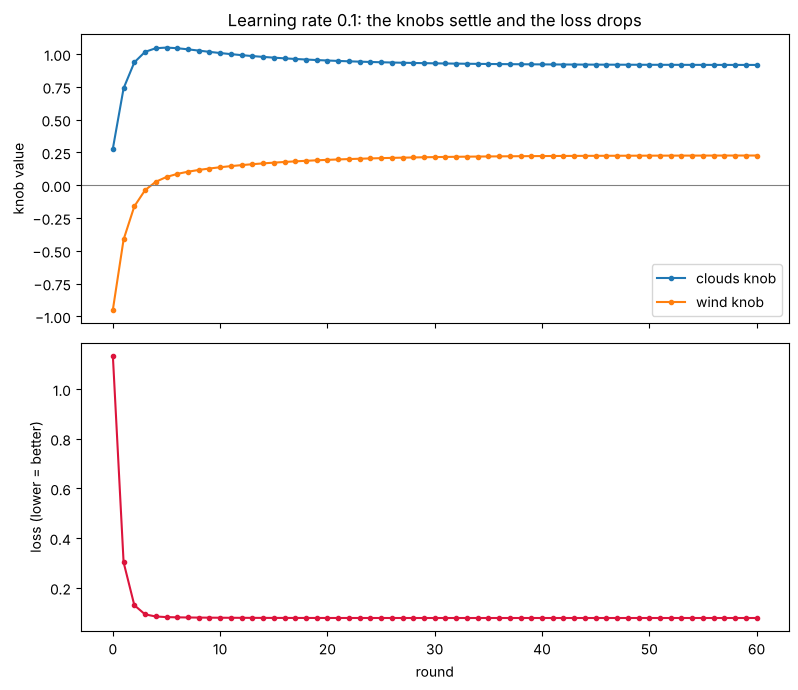

In [8]:
import matplotlib.pyplot as plt   # matplotlib: a library for drawing graphs

def plot_history(history, title="Training"):
    rounds = [row[0] for row in history]
    clouds_knobs = [row[1] for row in history]
    wind_knobs = [row[2] for row in history]
    losses = [row[3] for row in history]

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    top.plot(rounds, clouds_knobs, marker=".", label="clouds knob")
    top.plot(rounds, wind_knobs, marker=".", label="wind knob")
    top.axhline(0, color="grey", linewidth=0.8)
    top.set_ylabel("knob value")
    top.set_title(title)
    top.legend()

    bottom.plot(rounds, losses, marker=".", color="crimson")
    bottom.set_ylabel("loss (lower = better)")
    bottom.set_xlabel("round")
    plt.tight_layout()
    plt.show()

plot_history(history, "Learning rate 0.1: the knobs settle and the loss drops")

### Bonus picture: training is walking downhill 🏔️

Imagine a map. Left–right is the **clouds knob**; up–down is the **wind knob**. Every point on the map is one possible pair of knob settings, and its colour shows the **loss** for those settings: **dark = low loss (good)**, bright = high loss (bad).

The white dots show where our knobs were after each round. Training starts at the red ✕ and walks **downhill** into the dark valley, one round at a time.

**Every AI model is trained this way.** Big models just have a "map" with billions of directions instead of 2.

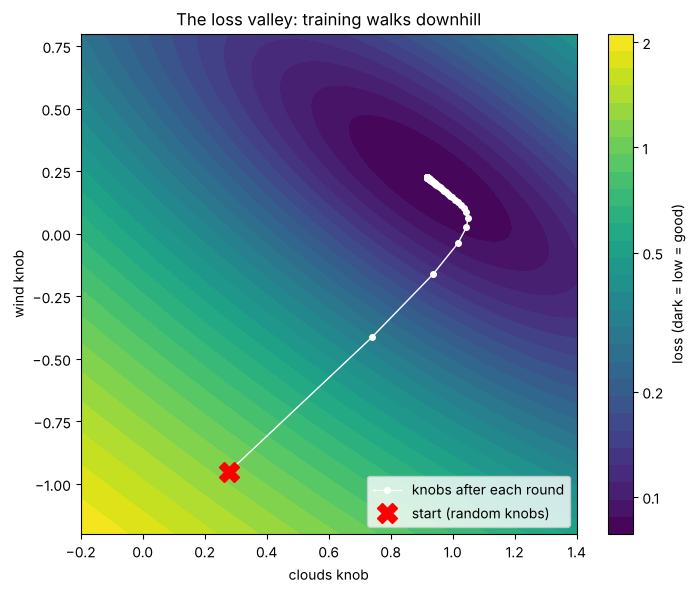

In [9]:
import numpy as np                       # numpy: does maths on many numbers at once
from matplotlib.colors import LogNorm    # a colour scale that shows the valley more clearly

# Work out the loss for a 200 × 200 grid of knob settings
clouds_grid, wind_grid = np.meshgrid(np.linspace(-0.2, 1.4, 200), np.linspace(-1.2, 0.8, 200))
loss_grid = np.zeros_like(clouds_grid)
for clouds, wind, rained in days:
    loss_grid += (clouds * clouds_grid + wind * wind_grid - rained) ** 2
loss_grid = loss_grid / len(days)

plt.figure(figsize=(8, 6.5))
plt.contourf(clouds_grid, wind_grid, loss_grid, levels=np.geomspace(loss_grid.min(), loss_grid.max(), 30),
             norm=LogNorm(), cmap="viridis")
colour_bar = plt.colorbar(label="loss (dark = low = good)")
colour_bar.set_ticks([0.1, 0.2, 0.5, 1, 2])
colour_bar.set_ticklabels(["0.1", "0.2", "0.5", "1", "2"])
path_clouds = [row[1] for row in history]
path_wind = [row[2] for row in history]
plt.plot(path_clouds, path_wind, "o-", color="white", markersize=4, linewidth=1, label="knobs after each round")
plt.plot(path_clouds[0], path_wind[0], "X", color="red", markersize=14, label="start (random knobs)")
plt.xlabel("clouds knob")
plt.ylabel("wind knob")
plt.title("The loss valley: training walks downhill")
plt.legend(loc="lower right")
plt.show()

## Step 8 — Use your trained model on a new day

Training is done. Now the model can make predictions for days it has never seen.

In Colab you'll see two **sliders** next to the code below. Move them, then run the cell (Shift + Enter). *(Outside Colab, just change the numbers `0.6` and `0.4` in the code.)*

In [10]:
# The final knobs after training = the last row of the diary
_, trained_clouds_knob, trained_wind_knob, _, _ = history[-1]

clouds = 0.6  #@param {type:"slider", min:0, max:1, step:0.1}
wind = 0.4    #@param {type:"slider", min:0, max:1, step:0.1}

score = rain_score(clouds, wind, trained_clouds_knob, trained_wind_knob)
print(f"Push from clouds: {clouds} × {trained_clouds_knob:.2f} = {clouds * trained_clouds_knob:.2f}")
print(f"Push from wind:   {wind} × {trained_wind_knob:.2f} = {wind * trained_wind_knob:.2f}")
print(f"Rain score = {score:.2f}  →  the model says: {model_says(score)}")

Push from clouds: 0.6 × 0.92 = 0.55
Push from wind:   0.4 × 0.23 = 0.09
Rain score = 0.64  →  the model says: Rain


**Try:** clouds 0.5 with wind 0.0, then clouds 0.5 with wind 1.0. Same clouds — the wind decides. Can you find the smallest amount of clouds that gives "Rain" when there is no wind at all?

## Step 9 — Your turn: 3 experiments 🧪 (this is where real understanding comes from)

Remember: **humans choose** the number of knobs, the data, and how much the knobs move (the learning rate). **The computer chooses the knob values.** These experiments let you play the human's part. (Jargon: the settings that humans choose are called **hyperparameters**.)

### Experiment A — How big should each nudge be? (the learning rate)
The cell below trains the same model 4 times with different learning rates and draws the 4 loss curves on one graph.

Learning rate 0.005: knobs clouds = +1.019, wind = -0.054  →  loss 0.0951, 10 of 12 correct
Learning rate 0.1  : knobs clouds = +0.917, wind = +0.226  →  loss 0.0783, 12 of 12 correct
Learning rate 2.0  : knobs clouds = +0.674, wind = -0.328  →  loss 0.2858, 7 of 12 correct
Learning rate 3.0  : 💥 EXPLODED in round 11 (the knobs became gigantic)


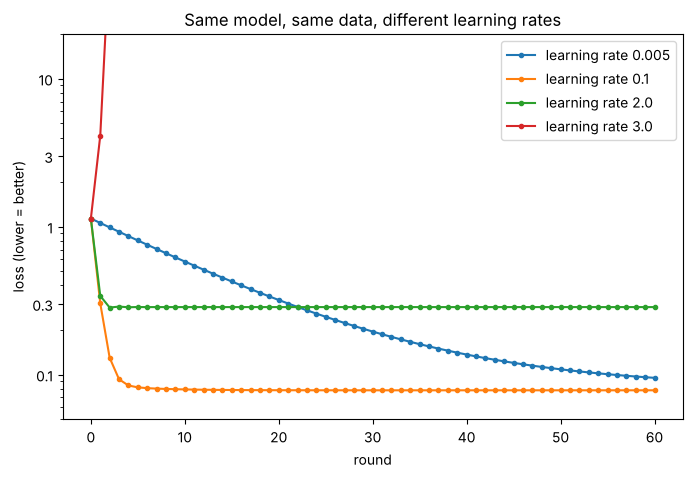

In [11]:
learning_rates_to_try = [0.005, 0.1, 2.0, 3.0]
rounds = 60

plt.figure(figsize=(8, 5))
for lr in learning_rates_to_try:
    h = train(learning_rate=lr, rounds=rounds, show=False)
    last_round, ck, wk, loss, correct = h[-1]
    if last_round < rounds:
        print(f"Learning rate {lr:<5}: 💥 EXPLODED in round {last_round + 1} (the knobs became gigantic)")
    else:
        print(f"Learning rate {lr:<5}: knobs clouds = {ck:+.3f}, wind = {wk:+.3f}  →  loss {loss:.4f}, {correct} of 12 correct")
    plt.plot([row[0] for row in h], [row[3] for row in h], marker=".", label=f"learning rate {lr}")

plt.yscale("log")       # each step up the side = 10 times more loss
plt.ylim(0.05, 20)      # the exploding line shoots off the top of the graph
plt.yticks([0.1, 0.3, 1, 3, 10], ["0.1", "0.3", "1", "3", "10"])
plt.xlabel("round")
plt.ylabel("loss (lower = better)")
plt.title("Same model, same data, different learning rates")
plt.legend()
plt.show()

### 👀 What you should see
- **0.005 (tiny steps):** the loss creeps down slowly. After 60 rounds the wind knob is *still negative* — the model hasn't finished learning (10 of 12 correct).
- **0.1 (good steps):** fast and smooth — all 12 correct.
- **2.0 (huge steps):** the loss drops at first, then gets **stuck** at a higher level (the flat green line). Every nudge jumps right over the bottom of the valley to the other side, so the knobs keep bouncing between the same spots and never reach the bottom: only 7 of 12 correct.
- **3.0 (giant steps):** every jump lands *higher* than the last, until the knobs fly off to gigantic numbers. Training has **exploded** 💥.

**Try it yourself:** change the numbers in `learning_rates_to_try` and run the cell again. What is the biggest learning rate that still works well? (Real AI engineers spend a lot of time on exactly this question.)

### Experiment B — Does the random start matter?
Change `seed=7` below to any other number (try 123 or 2026) and run it. The starting knobs will be different. Where do they end up?

In [12]:
history_b = train(learning_rate=0.1, rounds=60, seed=7)

Round | Clouds knob | Wind knob |  Loss  | Correct days
------+-------------+-----------+--------+-------------
    0 |   -0.352    |  -0.698   | 1.5831 | 6 of 12
    1 |   +0.248    |  -0.099   | 0.3914 | 6 of 12
    2 |   +0.528    |  +0.163   | 0.1464 | 8 of 12
    3 |   +0.663    |  +0.274   | 0.0955 | 12 of 12
    4 |   +0.731    |  +0.317   | 0.0844 | 12 of 12
    5 |   +0.769    |  +0.330   | 0.0817 | 12 of 12
    6 |   +0.792    |  +0.330   | 0.0808 | 12 of 12
    7 |   +0.807    |  +0.325   | 0.0803 | 12 of 12
    8 |   +0.819    |  +0.318   | 0.0799 | 12 of 12
    9 |   +0.829    |  +0.310   | 0.0796 | 12 of 12
   10 |   +0.838    |  +0.303   | 0.0794 | 12 of 12
   20 |   +0.887    |  +0.256   | 0.0785 | 12 of 12
   30 |   +0.905    |  +0.238   | 0.0783 | 12 of 12
   40 |   +0.912    |  +0.231   | 0.0783 | 12 of 12
   50 |   +0.915    |  +0.228   | 0.0783 | 12 of 12
   60 |   +0.916    |  +0.227   | 0.0783 | 12 of 12


Different start, **same ending**: clouds ≈ 0.92, wind ≈ 0.23. This simple model has just **one valley**, so every start rolls down to the same bottom. Big models have hugely complicated landscapes with many valleys; different starts end up in different places that work about equally well.

### Experiment C — What if the data has a strange day?
Real data is messy. Let's add a 13th day when it **rained under a clear sky with no wind** — very unusual.

In [13]:
days_with_strange_day = days + [(0.1, 0.1, 1)]   # day 13: clear sky, no wind... but it rained!

history_c = train(learning_rate=0.1, rounds=60, data=days_with_strange_day, show=False)
_, ck, wk, _, _ = history_c[-1]
show_guesses(ck, wk, data=days_with_strange_day)

Knobs: clouds = 0.936, wind = 0.240

Day | Clouds | Wind | Score | Model says | Really  | Right?
----+--------+------+-------+------------+---------+-------
  1 |  0.9   | 0.9  |  1.06 | Rain       | Rain    |   ✓
  2 |  0.1   | 0.1  |  0.12 | No rain    | No rain |   ✓
  3 |  0.8   | 0.3  |  0.82 | Rain       | Rain    |   ✓
  4 |  0.1   | 0.9  |  0.31 | No rain    | No rain |   ✓
  5 |  0.6   | 0.8  |  0.75 | Rain       | Rain    |   ✓
  6 |  0.3   | 0.3  |  0.35 | No rain    | No rain |   ✓
  7 |  0.5   | 1.0  |  0.71 | Rain       | Rain    |   ✓
  8 |  0.5   | 0.0  |  0.47 | No rain    | No rain |   ✓
  9 |  1.0   | 0.5  |  1.06 | Rain       | Rain    |   ✓
 10 |  0.0   | 0.4  |  0.10 | No rain    | No rain |   ✓
 11 |  0.7   | 0.5  |  0.77 | Rain       | Rain    |   ✓
 12 |  0.4   | 0.5  |  0.49 | No rain    | No rain |   ✓
 13 |  0.1   | 0.1  |  0.12 | No rain    | Rain    |   ✗

Loss = 0.1324    Correct: 12 out of 13 days


The model gets 12 of 13 right — only the strange day 13 is wrong. The knobs moved only a little (clouds 0.92 → 0.94, wind 0.23 → 0.24), and the loss went up (0.078 → 0.132) because one answer just can't be matched.

This is usually **good**: a model should learn the **pattern**, not memorise every odd exception. (Jargon: a model that memorises its training examples instead of learning the pattern is **overfitting**. It looks great on the data it trained on, but fails on new data.)

## Step 10 — From 2 knobs to giant AI models (and why they need so much memory)

Every knob is stored as a number in memory. AI models are usually shipped at **2 bytes per knob** (a "16-bit" number; 1 byte = 8 bits).

So: **memory ≈ number of knobs × bytes per knob.**

(Indian numbering helps here: **1 billion = 100 crore**. So a "7B" model has 700 crore knobs!)

In [14]:
models = [
    ("Our rain model", 2),
    ("1B model", 1_000_000_000),
    ("7B model", 7_000_000_000),
    ("70B model", 70_000_000_000),
    ("400B model", 400_000_000_000),
]

print("Model           |            Knobs |   In crore | Memory at 2 bytes per knob")
print("----------------+------------------+------------+---------------------------")
for name, knobs in models:
    memory_bytes = knobs * 2
    if memory_bytes < 1000:
        memory_text = f"{memory_bytes} bytes"
    else:
        memory_text = f"{memory_bytes / 1_000_000_000:,.0f} GB"     # 1 GB ≈ 1 billion bytes
    crore = f"{knobs / 10_000_000:,.0f}" if knobs >= 10_000_000 else "—"
    print(f"{name:<15} | {knobs:>16,} | {crore:>10} | {memory_text}")

Model           |            Knobs |   In crore | Memory at 2 bytes per knob
----------------+------------------+------------+---------------------------
Our rain model  |                2 |          — | 4 bytes
1B model        |    1,000,000,000 |        100 | 2 GB
7B model        |    7,000,000,000 |        700 | 14 GB
70B model       |   70,000,000,000 |      7,000 | 140 GB
400B model      |  400,000,000,000 |     40,000 | 800 GB


**The big idea:** the training loop you ran today — *guess → measure the loss → nudge the knobs downhill → repeat* — is the same core idea used to train ChatGPT-style models. The differences are scale and tricks: billions of knobs, many layers of formulas stacked on top of each other, a smarter nudge rule (a popular one is called **Adam**), and GPUs doing millions of multiplications at the same time.

A 7B model needs about **14 GB** just to hold its knobs. Your goal is to fit models into **1–2 GB**. The most important tool for that is **quantization** — storing each knob with fewer bits. That's **Lesson 2**.

## Summary — what you saw today

| Idea | What it means | Where you saw it |
|---|---|---|
| **Knob (parameter)** | An adjustable number inside the model | `clouds_knob`, `wind_knob` |
| **Score** | Inputs × knobs, added up | `rain_score(...)` |
| **Loss** | Average squared error. Lower = better | 1.13 at the start → 0.078 after training |
| **Nudge rule (gradient descent)** | knob = knob − learning rate × error × input | Step 5 |
| **Learning rate** | How big each nudge is (a human chooses it) | 0.005 too slow, 0.1 good, 3.0 explodes |
| **Round (epoch)** | One pass through all the training data | 60 rounds = 720 nudges |
| **Hyperparameters** | Settings humans choose: learning rate, rounds, number of knobs | Experiments A–C |

> **Hinglish mein recap:** Model random knobs se shuru hota hai. Har din ke liye guess karta hai, galti (error) dekhta hai, aur knobs ko thoda sa us direction mein ghumata hai jisse galti kam ho. 720 baar aisa karke model ne khud seekh liya ki clouds, wind se lagbhag 4 guna zyada important hain. Learning rate bahut chhota → bahut dheere seekhta hai; bahut bada → knobs "explode" ho jaate hain.

### Check yourself (click a question to see the answer)

<details><summary><b>1.</b> On a day with clouds = 0 and wind = 0.8, which knob moves during a nudge?</summary>

Only the **wind knob**. The clouds input was 0, so the clouds knob played no part in that guess and doesn't move.
</details>

<details><summary><b>2.</b> The model's score was 0.9 but it did not rain. Will the knobs go up or down?</summary>

**Down.** Error = 0.9 − 0 = +0.9 (positive = guessed too high), so "knob − learning rate × positive × input" makes the knob smaller.
</details>

<details><summary><b>3.</b> Why didn't the loss reach 0?</summary>

The right answers are exactly 0 or 1, but a 2-knob formula can't produce exactly those numbers for all 12 days at once. The model found the best compromise — and still got every day right.
</details>

<details><summary><b>4.</b> A model has 3 billion knobs stored at 2 bytes each. Roughly how much memory does it need?</summary>

3,000,000,000 × 2 = 6,000,000,000 bytes ≈ **6 GB**.
</details>

### ➡️ Next: Lesson 2 — Quantization
Shrink a model by storing its knobs with fewer bits, then **measure** how much smaller it gets and how much worse it becomes. Open `lesson02_quantization.ipynb`.